# Deep Learning: Text Sentiment Classification

**Goal:** classify short reviews as positive or negative using PyTorch. This project uses tokenization/TF-IDF features, a feed-forward neural network, a stratified train/validation/test split, training curves, test metrics, and a saved model for inference.

> **Dataset limitation:** the bundled 370-row balanced example corpus is curated for coursework and is not a real-world benchmark. Results demonstrate the workflow rather than production-level sentiment understanding.

For setup and exact command-line instructions, see `README.md`.

In [1]:
from pathlib import Path
import sys, json, platform
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "train_sentiment.py").exists():
    PROJECT_DIR = PROJECT_DIR.parent
if not (PROJECT_DIR / "train_sentiment.py").exists():
    raise FileNotFoundError("Open/run this notebook from the project folder so train_sentiment.py is discoverable.")
sys.path.insert(0, str(PROJECT_DIR))
print("Project:", PROJECT_DIR)
print("Python:", platform.python_version())

Project: /mnt/data/Deep_Learning_Sentiment_Project
Python: 3.13.5


## 1. Load and inspect the dataset

The CSV contains raw review text and a `label` column. Class labels are balanced in this educational corpus.

Rows: 370
Missing values:
 text     0
label    0
dtype: int64


,text,label
0,The film kept me engaged from the opening scen...,positive
1,The acting felt natural and the characters wer...,positive
2,I enjoyed every minute of this warm and funny ...,positive
3,The ending was satisfying without feeling pred...,positive
4,The soundtrack adds emotion without overpoweri...,positive
5,The director balances suspense and humor remar...,positive
6,The visuals are beautiful and the pacing stays...,positive
7,The lead performance is convincing and full of...,positive


,count
label,
positive,185
negative,185


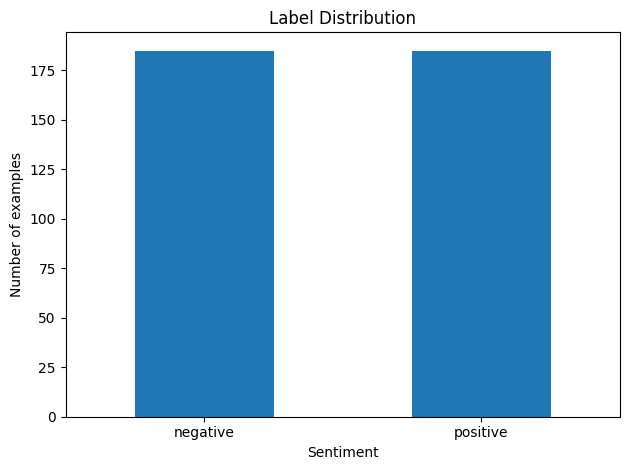

In [2]:
data = pd.read_csv(PROJECT_DIR / "data" / "sentiment_dataset.csv")
print("Rows:", len(data))
print("Missing values:\n", data.isna().sum())
display(data.head(8))
display(data["label"].value_counts().rename_axis("label").to_frame("count"))
ax = data["label"].value_counts().reindex(["negative", "positive"]).plot(kind="bar", title="Label Distribution", rot=0)
ax.set_xlabel("Sentiment"); ax.set_ylabel("Number of examples"); plt.tight_layout(); plt.show()

## 2. Preprocessing and model design

`TfidfVectorizer` lowercases and tokenizes each review, then builds unigram and bigram features. It is fitted on the training partition only. The PyTorch MLP has a dense hidden layer with ReLU and dropout, followed by a two-class output layer. The script uses a stratified 80/20 train/test split and reserves a stratified validation slice from the training portion for early stopping. A Logistic Regression baseline is included for context.

## 3. Train, validate, and evaluate

The next cell runs the canonical training script logic. It saves the trained state dictionary, fitted vectorizer, numeric metrics, predictions, and plots into `artifacts/`. Re-running training replaces these generated artifacts.

In [3]:
from train_sentiment import train
metrics = train(epochs=60, batch_size=32, seed=42, patience=12)

Epoch 01/60 | train_loss=0.6946 | val_loss=0.6946
Epoch 02/60 | train_loss=0.6928 | val_loss=0.6940
Epoch 03/60 | train_loss=0.6899 | val_loss=0.6934
Epoch 04/60 | train_loss=0.6863 | val_loss=0.6929
Epoch 05/60 | train_loss=0.6828 | val_loss=0.6921
Epoch 06/60 | train_loss=0.6795 | val_loss=0.6913
Epoch 07/60 | train_loss=0.6741 | val_loss=0.6903
Epoch 08/60 | train_loss=0.6683 | val_loss=0.6889
Epoch 09/60 | train_loss=0.6611 | val_loss=0.6871
Epoch 10/60 | train_loss=0.6542 | val_loss=0.6855
Epoch 11/60 | train_loss=0.6437 | val_loss=0.6835
Epoch 12/60 | train_loss=0.6371 | val_loss=0.6813
Epoch 13/60 | train_loss=0.6229 | val_loss=0.6787
Epoch 14/60 | train_loss=0.6124 | val_loss=0.6760
Epoch 15/60 | train_loss=0.5989 | val_loss=0.6734


Epoch 16/60 | train_loss=0.5809 | val_loss=0.6702
Epoch 17/60 | train_loss=0.5689 | val_loss=0.6668
Epoch 18/60 | train_loss=0.5496 | val_loss=0.6636
Epoch 19/60 | train_loss=0.5306 | val_loss=0.6602
Epoch 20/60 | train_loss=0.5143 | val_loss=0.6572
Epoch 21/60 | train_loss=0.4978 | val_loss=0.6539
Epoch 22/60 | train_loss=0.4803 | val_loss=0.6506
Epoch 23/60 | train_loss=0.4627 | val_loss=0.6472
Epoch 24/60 | train_loss=0.4385 | val_loss=0.6440
Epoch 25/60 | train_loss=0.4222 | val_loss=0.6410
Epoch 26/60 | train_loss=0.4070 | val_loss=0.6379
Epoch 27/60 | train_loss=0.3831 | val_loss=0.6350


Epoch 28/60 | train_loss=0.3809 | val_loss=0.6322
Epoch 29/60 | train_loss=0.3564 | val_loss=0.6296
Epoch 30/60 | train_loss=0.3407 | val_loss=0.6270
Epoch 31/60 | train_loss=0.3291 | val_loss=0.6246
Epoch 32/60 | train_loss=0.3049 | val_loss=0.6221
Epoch 33/60 | train_loss=0.3004 | val_loss=0.6203
Epoch 34/60 | train_loss=0.2887 | val_loss=0.6182
Epoch 35/60 | train_loss=0.2819 | val_loss=0.6165
Epoch 36/60 | train_loss=0.2577 | val_loss=0.6148
Epoch 37/60 | train_loss=0.2432 | val_loss=0.6135


Epoch 38/60 | train_loss=0.2362 | val_loss=0.6119
Epoch 39/60 | train_loss=0.2259 | val_loss=0.6112
Epoch 40/60 | train_loss=0.2142 | val_loss=0.6106
Epoch 41/60 | train_loss=0.2073 | val_loss=0.6101
Epoch 42/60 | train_loss=0.1983 | val_loss=0.6098
Epoch 43/60 | train_loss=0.1988 | val_loss=0.6090
Epoch 44/60 | train_loss=0.1800 | val_loss=0.6079
Epoch 45/60 | train_loss=0.1748 | val_loss=0.6073
Epoch 46/60 | train_loss=0.1710 | val_loss=0.6068
Epoch 47/60 | train_loss=0.1578 | val_loss=0.6061
Epoch 48/60 | train_loss=0.1479 | val_loss=0.6059
Epoch 49/60 | train_loss=0.1441 | val_loss=0.6057
Epoch 50/60 | train_loss=0.1421 | val_loss=0.6054
Epoch 51/60 | train_loss=0.1352 | val_loss=0.6050
Epoch 52/60 | train_loss=0.1316 | val_loss=0.6049


Epoch 53/60 | train_loss=0.1232 | val_loss=0.6055
Epoch 54/60 | train_loss=0.1146 | val_loss=0.6052
Epoch 55/60 | train_loss=0.1210 | val_loss=0.6050
Epoch 56/60 | train_loss=0.1074 | val_loss=0.6047
Epoch 57/60 | train_loss=0.1188 | val_loss=0.6047
Epoch 58/60 | train_loss=0.1126 | val_loss=0.6045
Epoch 59/60 | train_loss=0.1060 | val_loss=0.6045
Epoch 60/60 | train_loss=0.0986 | val_loss=0.6046



Held-out TEST metrics:
  Pytorch Mlp
    accuracy   0.6216
    precision  0.6154
    recall     0.6486
    f1         0.6316
    roc_auc    0.6486
  Logistic Regression Baseline
    accuracy   0.5541
    precision  0.5556
    recall     0.5405
    f1         0.5479
    roc_auc    0.6844
  Split sizes: train=236, validation=60, test=74; TF-IDF features=1996; device=cpu

PyTorch MLP classification report:
              precision    recall  f1-score   support

    negative       0.63      0.59      0.61        37
    positive       0.62      0.65      0.63        37

    accuracy                           0.62        74
   macro avg       0.62      0.62      0.62        74
weighted avg       0.62      0.62      0.62        74


Saved model: /mnt/data/Deep_Learning_Sentiment_Project/artifacts/sentiment_mlp.pth


## 4. Test metrics

Accuracy, precision, recall, F1-score, and ROC-AUC are reported for the held-out test set. ROC-AUC describes ranking ability across thresholds; it is possible for a model to have better accuracy at one threshold but lower ROC-AUC than a baseline.

In [4]:
metrics_path = PROJECT_DIR / "artifacts" / "metrics.json"
metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
metric_table = pd.DataFrame(metrics["pytorch_mlp"], index=["PyTorch MLP"]).T
metric_table = metric_table.rename(columns={"PyTorch MLP":"Score"})
comparison = pd.DataFrame(metrics["pytorch_mlp"], index=["PyTorch MLP"]).T
comparison["Logistic Regression"] = pd.Series(metrics["logistic_regression_baseline"])
display(comparison.rename_axis("Metric"))
print("Split sizes:", {k: metrics[k] for k in ["train_rows", "validation_rows", "test_rows"]})
print("Number of TF-IDF features:", metrics["vocabulary_features"])
print("Best validation-loss epoch:", metrics["best_epoch"])

,PyTorch MLP,Logistic Regression
Metric,,
accuracy,0.621622,0.554054
precision,0.615385,0.555556
recall,0.648649,0.540541
f1,0.631579,0.547945
roc_auc,0.648649,0.684441


Split sizes: {'train_rows': 236, 'validation_rows': 60, 'test_rows': 74}
Number of TF-IDF features: 1996
Best validation-loss epoch: 58


## 5. Training curves and evaluation plots

training_curves.png


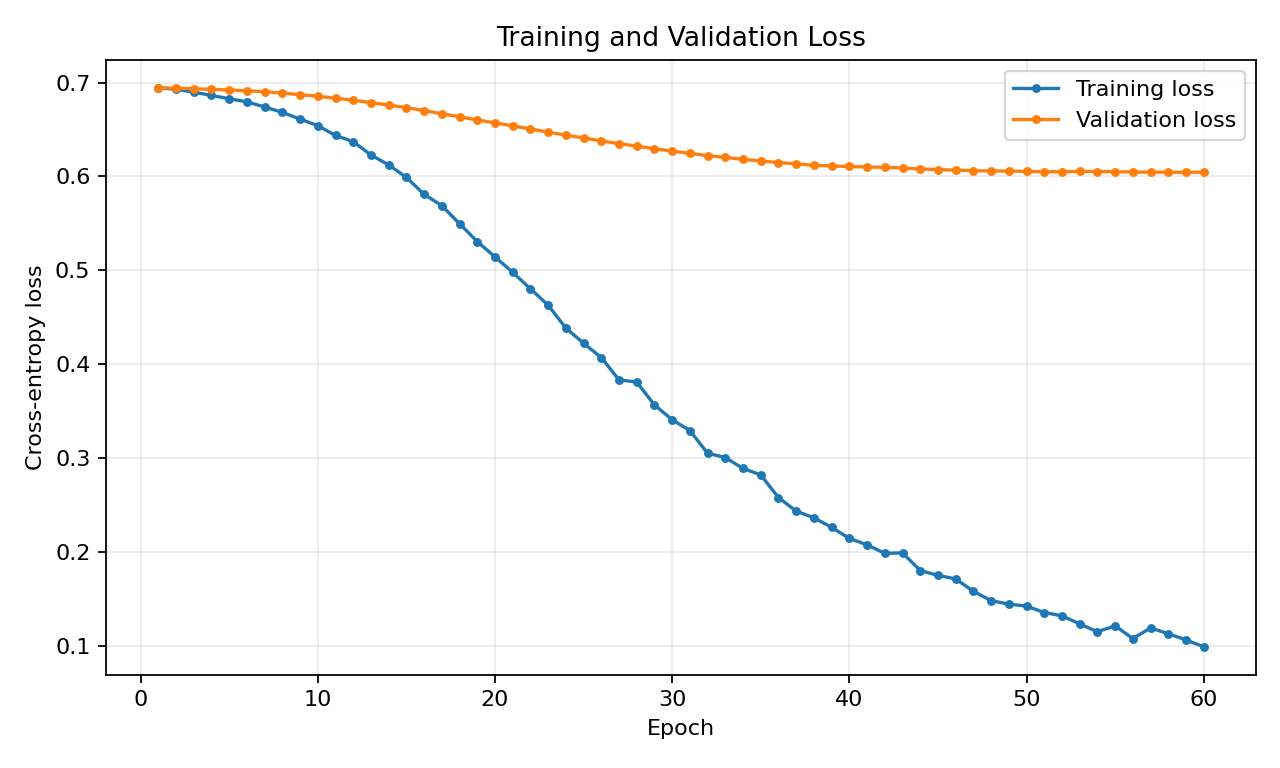

confusion_matrix.png


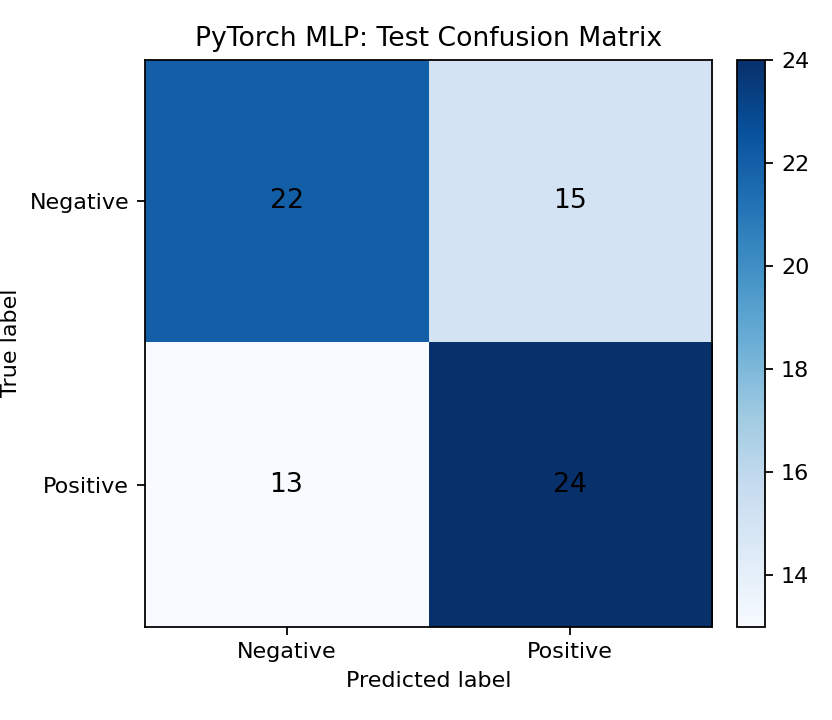

roc_curve.png


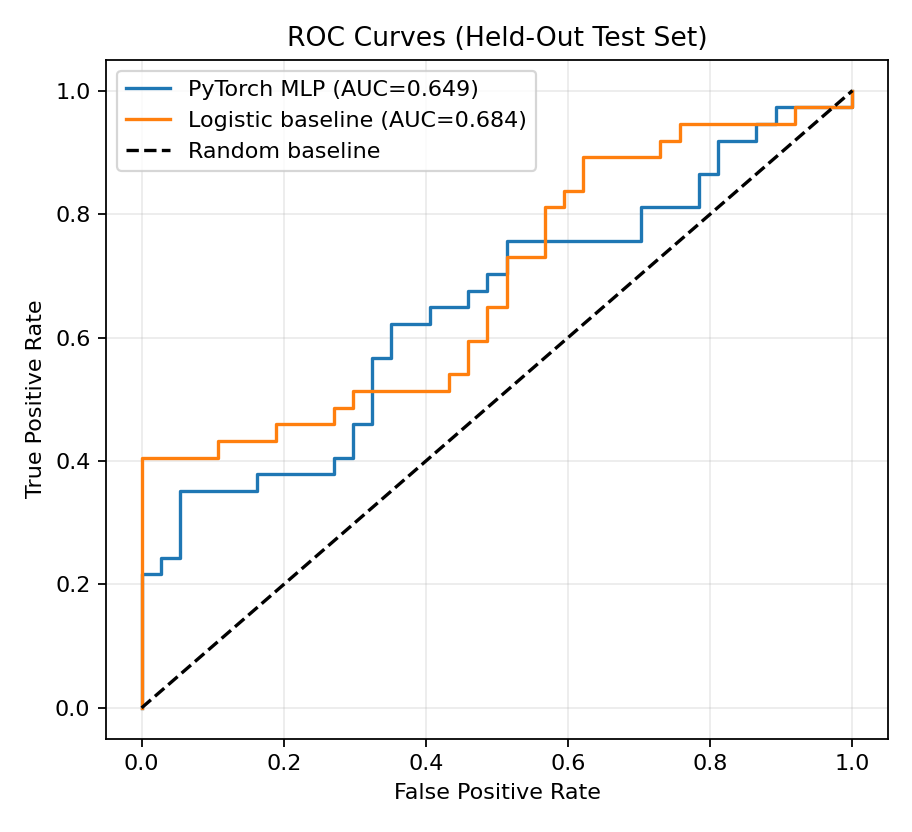

model_comparison.png


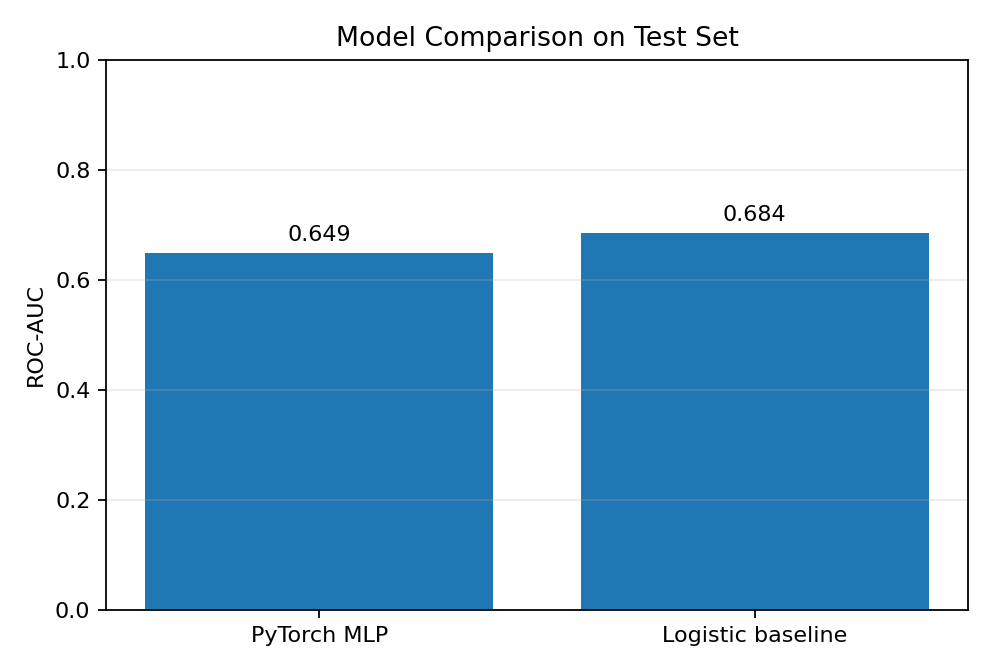

In [5]:
for filename in ["training_curves.png", "confusion_matrix.png", "roc_curve.png", "model_comparison.png"]:
    print(filename)
    display(Image(filename=str(PROJECT_DIR / "artifacts" / filename)))

## 6. Load the saved model and run inference

The `.pth` weights and fitted TF-IDF vectorizer must both be present for inference. Softmax scores are model scores and are not calibrated probabilities.

In [6]:
from predict_sentiment import predict
examples = [
    "The delivery was quick and the product works perfectly.",
    "The app crashes constantly and support did not help.",
]
for text in examples:
    print(json.dumps(predict(text), indent=2))

{
  "text": "The delivery was quick and the product works perfectly.",
  "predicted_sentiment": "positive",
  "positive_probability": 0.794,
  "negative_probability": 0.206,
  "threshold": 0.5
}
{
  "text": "The app crashes constantly and support did not help.",
  "predicted_sentiment": "negative",
  "positive_probability": 0.0653,
  "negative_probability": 0.9347,
  "threshold": 0.5
}


## 7. Pretrained transfer learning (optional)

An optional script is included to fine-tune pretrained DistilBERT when internet access is available. The pre-generated model in this package is the offline-capable PyTorch MLP; the optional DistilBERT weights have not been downloaded or fine-tuned here.

```bash
pip install "transformers>=4.40" "accelerate>=0.29"
python train_distilbert_transfer.py --epochs 3 --batch-size 8
```

## Conclusion

This notebook demonstrates a complete, reproducible deep-learning text-classification workflow. The held-out set is small, so scores can vary and should not be generalized to live customer feedback. A larger representative corpus and further validation would be required for real-world use.